## Practicum Vision & Language NLP - Uncertainty Quantification with Multimodal LLMs

In this notebook, we will evaluate several multimodal Vision & Language LLMs on a Medical Visual Question Answering task. We will use the following dataset: [GMAI-MMBench: A Comprehensive Multimodal Evaluation Benchmark Towards General Medical AI.](https://huggingface.co/datasets/OpenGVLab/GMAI-MMBench) The dataset is released under the Apache 2.0 license, and you will work on a pre-processed subset prepared by us.

We will evaluate several models:
- `Qwen2-VL-2B-Instruct` and `Medgemma-4b-it` (smaller models that can be run directly on Colab; output files are also provided in case of issues).
- `Qwen2.5-VL-32B-Instruct` and `GPT-5-mini` (larger models - we provide the output files).

Output files are named according to the following template:
`outputs_{model_name}-sample_{sample_answers}-temp_{temperature}.tsv`

### Setup

- In Runtime, select Change runtime type, then choose **T4 GPU** as the hardware accelerator.  

- Log into Hugging Face and accept the license agreement for [Qwen2-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen2-VL-2B-Instruct) and [Medgemma-4b-it](https://huggingface.co/google/medgemma-4b-it). Attention, this may take a while to be processed.

- Set your Hugging Face token as the variable **HF_TOKEN** in the Secrets tab (left menu, key icon) or paste your token in the "your_token" in the required field. Make sure not to accidentaly share it.


### Important Note

This challenging assignment gives you plenty of freedom to explore and be creative. You are expected to demonstrate independence, formulate your own hypotheses, and test them empirically. Since this is a cutting-edge research area with many open questions, take the opportunity to investigate, experiment, and follow your curiosity! :)


In [5]:
from typing import List, Dict, Any, Tuple, Generator, Optional, Union
import random
import string, os, sys, glob
import pandas as pd
import numpy as np

from PIL import Image
from tqdm import tqdm
import torch
import ast

In [6]:
import os
from dotenv import load_dotenv

# Load variables from the .env file into the environment
load_dotenv()

# Retrieve the token
hf_token = os.environ.get("HF_TOKEN")

if not hf_token:
    raise ValueError("HF_TOKEN not found. Please check your .env file.")

os.environ["HF_TOKEN"] = hf_token

In [5]:
!gdown --folder https://drive.google.com/drive/folders/1dNoFV9GvDhMdTjM2P2oHW00-f9oPMxnf -O ./data
!unzip -q ./data/filtered_images.zip -d ./data/images/

Using cookies from /Users/samha/.cache/gdown/cookies.txt
Retrieving folder contents
Retrieving folder 1MxSEpKZWI26Gl2dVdvRd2uMn7Eimr9dC model_responses
Processing file 1tG8zYy11gXQ-puRQocji6OOKogHR12Pi outputs_gpt5-mini_no-logprobs.tsv
Processing file 1GVFn2qKdDJxtEbbrufC0W7eULvAZMyPa outputs_medgemma-4b-it-temp_0.2.tsv
Processing file 1BAx2jUeuUbgRX6joWR94vdS0nsqCNf-I outputs_medgemma-4b-it-temp_0.6.tsv
Processing file 1JK7ACAkPVKIyEZ39RtVru3GDgUvMk_8J outputs_medgemma-4b-it-temp_1.0.tsv
Processing file 18cSUZl93yG167twxUY_gmEaMYXDOfi3q outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv
Processing file 1pxUlsk9rK67Uo9mOSxKKOebMzGxPYXS9 outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
Processing file 1WlgSroLtv5STSufSC4qRM419KW5YRBod outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv
Processing file 1HjbP_JjNq1gkqsz-RiXff-c5M_tvPvb8 outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv
Processing file 11XjxhRI7j-xOEtnTYnE7-v8pFTOk6jIh outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv
Processing file 1FSfXTQj2ytMsCfO0Iy_xoeP

# 1. Inference (run on GPUs)

## Load and Prepare Model Inputs

In [6]:
def add_options_dict(df_raw: pd.DataFrame) -> pd.DataFrame:  # prepare the multiple-choice question format
    option_cols = [col for col in df_raw.columns if col in list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")]

    def _make_dict(row):
        return {col: row[col] for col in option_cols if pd.notna(row[col])}

    out = df_raw.copy()
    out["options"] = out.apply(_make_dict, axis=1)
    return out

def construct_prompt(row) -> str:  # prepare the prompt for the model
    PROMPT_TEMPLATE = """Question: ({question})
Provide a concise answer and start your response with the letter of the selected option in square brackets. Options:
(
{options}
)
Your Answer:
"""
    question = row["question"]
    options = {
        letter: row[letter]
        for letter in string.ascii_uppercase[:5]
        if letter in row and row[letter] and str(row[letter]).strip() and not pd.isna(row[letter])
    }

    formatted_options = "\n".join(
        f"[{letter}] {option}"
        for letter, option in options.items()
    )

    return PROMPT_TEMPLATE.format(
        question=question,
        options=formatted_options
    )

In [7]:
input_tsv = "data/GMAI_mm_bench_dataset.tsv"  # the pre-processed dataset we provide
df = pd.read_csv(input_tsv, sep="\t")

df = add_options_dict(df)
df["prompt"] = df.apply(lambda row: construct_prompt(row), axis=1)
data_records: List[dict] = df.to_dict(orient="records")

In [8]:
df.head()  # inspect the data

,index,question,A,B,C,D,E,answer,category,clinical VQA task,department,perceptual granularity,modality,original task,image_path,options,prompt
0,398,Which of the following options best matches th...,fascia uncovered kidney parenchyma,lung,fascia covered kidney parenchyma,heart,clavicles,D,heart,Organ Recognition - Thorax,Cardiovascular Surgery,Contour level,X-ray,SEG_2D,398.jpg,"{'A': 'fascia uncovered kidney parenchyma', 'B...",Question: (Which of the following options best...
1,4322,"Observe the image, please select the option th...",grade 2 (minimal),grade 3 (moderate),grade 4 (severe),grade 1 (doubtful),NaN,A,grade 2 (minimal),Severity Grading,Sports Medicine,Image level,X-ray,CLS_2D,4322.jpg,"{'A': 'grade 2 (minimal)', 'B': 'grade 3 (mode...","Question: (Observe the image, please select th..."
2,2627,Considering the symptoms visible in the pictur...,COVID 19,viral pneumonia,normal chest x ray,NaN,NaN,B,viral pneumonia,Disease Diagnosis,Pulmonary Medicine,Image level,X-ray,CLS_2D,2627.jpg,"{'A': 'COVID 19', 'B': 'viral pneumonia', 'C':...",Question: (Considering the symptoms visible in...
3,70,Focus on the square-highlighted area of this X...,pulmonary mass,diffuse pulmonary nodule,pleural effusion,pulmonary calcification,NaN,A,pulmonary mass,Disease Diagnosis,Pulmonary Medicine,Box level,X-ray,DET_2D,70.jpg,"{'A': 'pulmonary mass', 'B': 'diffuse pulmonar...",Question: (Focus on the square-highlighted are...
4,4525,Choose the description that best matches the i...,negative for pneumonia,typical appearance of COVID-19,indeterminate appearance of COVID-19,atypical appearance of COVID-19,NaN,C,indeterminate appearance of COVID-19,Severity Grading,Pulmonary Medicine,Image level,X-ray,CLS_2D,4525.jpg,"{'A': 'negative for pneumonia', 'B': 'typical ...",Question: (Choose the description that best ma...


In [9]:
len(df) # we have 300 image-question pairs

300

In [ ]:
#q1
# data exploration
print(df['clinical VQA task'].value_counts())

print(df['department'].value_counts())

clinical VQA task
Disease Diagnosis                    182
Organ Recognition - Thorax            25
Bone                                  22
Severity Grading                      16
Organ Recognition - Abdomen           14
Organ Recognition - Head and Neck     13
Blood Vessels Recognition             10
Muscle                                 7
Organ Recognition - Pelvic             7
Attribute Recognition                  4
Name: count, dtype: int64
department
Pulmonary Medicine                            76
Sports Medicine                               50
Orthopedic Surgery                            49
Gastroenterology and Hepatology               32
Oncology (Medical)                            17
Cardiovascular Surgery                        14
Hematology                                    14
Otolaryngology (ENT)/Head and Neck Surgery     9
Urology                                        8
Neurosurgery                                   7
Endocrinology                                

In [ ]:
#q2
# average length
df['word_count'] = df['question'].apply(lambda x: len(str(x).split()))
average_length = df['word_count'].mean()
print("average length of questions:", average_length)

# direct phrased with question mark
print("direct phrased with question mark:", df['question'].str.contains(r'\?$').sum())

# frequency of number of answer options
df['num_options_count'] = df[['A', 'B', 'C', 'D', 'E']].notna().sum(axis=1)
num_options_count = df['num_options_count'].value_counts().sort_index()

print("frequency of number of answer options:\n", num_options_count)

# gold answer letter distribution
print("gold answer letter distribution:\n", df['answer'].value_counts().sort_index())

# baseline 1: expected accuracy of a model that picks an option uniformly at random
print("baseline 1: expected accuracy of a model that picks an option uniformly at random:", (1 / df['num_options_count'].mean()))

# baseline 2: expected accuracy of a model that always picks the most frequent gold letter
most_frequent_gold_letter = df['answer'].value_counts().idxmax()
print("baseline 2: expected accuracy of a model that always picks the most frequent gold letter:", (df['answer'] == most_frequent_gold_letter).mean())    

average length of questions: 14.316666666666666
direct phrased with question mark: 274
frequency of number of answer options:
 num_options_count
2      7
3      1
4    210
5     82
Name: count, dtype: int64
gold answer letter distribution:
 answer
A    67
B    75
C    70
D    69
E    19
Name: count, dtype: int64
baseline 1: expected accuracy of a model that picks an option uniformly at random: 0.2367797947908445
baseline 2: expected accuracy of a model that always picks the most frequent gold letter: 0.25


In [ ]:
#q3
# example question + answer
print(df['question'].iloc[68])
print(df.iloc[68][['A', 'B', 'C', 'D', 'E']])
print(df['answer'].iloc[68])

Please identify the part shown in the image.
A          proximal interphalangeal
B    first proximal interphalangeal
C                            radius
D               metacarpophalangeal
E                               NaN
Name: 68, dtype: object
B


## a. Inference with Qwen2-VL-2B-Instruct

In [13]:
from transformers import AutoModelForImageTextToText, AutoProcessor, GenerationConfig
from PIL import Image

model_id = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype='auto',
    device_map='auto'
)

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype='auto',
    device_map='auto'
).eval()

/Users/samha/Desktop/medical_ai/part4/uncertainty-quantification-group-17/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 729/729 [00:00<00:00, 70542.11it/s]


In [ ]:
model.device # verify this is running on 'cuda' (MPS on macbook)

device(type='mps', index=0)

In [11]:
images_dir = "data/images"

def format_inputs(batch_item: Dict[str, Any]) -> Dict[str, Any]:
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": batch_item["prompt"]},
                {"type": "image"},
            ],
        }
    ]

    return {
        **batch_item,
        "messages": messages,
        "image": Image.open(os.path.join(images_dir, batch_item["image_path"]))
    }

In [ ]:
#q4
batch_size = 4
max_new_tokens = 32
temperature = 0.6  # <-- Pay close attention to this parameter: you will be asked to explore how changing it affects the results.
top_p = 0.9
sample_answers = 10  # we sample 10 responses for each question.

# Repeat each element in data list 10 times
data = [item for item in data_records for _ in range(sample_answers)]

#if the block takes too long to run, use a subset for initial inspection
#data = data[:100]

results = []
for i in tqdm(range(0, len(data), batch_size)):
    batch = data[i:i + batch_size]
    batch = [format_inputs(item) for item in batch]

    prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
    images_batch = [item["image"] for item in batch]

    inputs = processor(
        images=images_batch,
        text=prompts_batch,
        return_tensors="pt",
        padding=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(**inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False if temperature == 0 else True,
            temperature=temperature,
            top_p=top_p,
            return_dict_in_generate=True,
            output_scores=True,
            output_logits=True,
            pad_token_id=processor.tokenizer.pad_token_id,
        )

    input_ids = inputs["input_ids"]

    for b_idx, item in enumerate(batch):
        input_len = input_ids[b_idx].shape[0]

        generated_tokens = outputs.sequences[b_idx, input_len:]
        generated_text = processor.decode(generated_tokens, skip_special_tokens=True)

        logprobs = []
        for j, logits in enumerate(outputs.logits):  # extract the probability associated to each generated token
            if j >= generated_tokens.shape[0]:  # Avoid out-of-bounds if gen shorter than scores
                break
            token_id = outputs.sequences[b_idx, input_len + j].item()
            probs = torch.nn.functional.softmax(logits[b_idx], dim=-1)
            logprob = torch.log(probs[token_id]).item()
            token_str = processor.tokenizer.decode([token_id])
            logprobs.append((token_str, logprob))

        row = df[df["index"] == item["index"]].iloc[0]

        results.append({
            "index": item["index"],
            "question": item["question"],
            "gold_label": item["answer"],
            "category": item["category"],
            'clinical VQA task': item['clinical VQA task'],
            'department': item['department'],
            'perceptual granularity': item['perceptual granularity'],
            'modality': item['modality'],
            'original task': item['original task'],
            'image_path':item['image_path'],
            "options": row["options"],
            "prompt": prompts_batch[b_idx],
            "response": generated_text,
            "logprobs": logprobs
        })

# save the generated responses
output_df = pd.DataFrame(results)
output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

filename = f"outputs_{os.path.split(model_id)[1]}-temp_{temperature}.tsv"
output_df.to_csv(os.path.join(output_folder, filename), index=False, sep="\t", encoding="utf-8")

100%|██████████| 750/750 [17:32<00:00,  1.40s/it]


In [97]:
import math

# investingating the output
print("response:", output_df.iloc[0]['response'])

print("token-log probability pairs:", output_df.iloc[0]['logprobs'])

# token log probability of first token into probability
print("token log probability of first token into probability:", math.exp(output_df.iloc[0]['logprobs'][0][1]))



response: [B] lung
token-log probability pairs: [('[B', -0.6402887105941772), (']', -0.0009353361674584448), (' lung', -0.006684181746095419), ('<|im_end|>', -0.00011325523519190028)]
token log probability of first token into probability: 0.5271402111077987


## b. Inference with medgemma-4b-it

In [ ]:
import gc

# Release the previous model and tensors from its inference loop.
for name in (
    "model", "processor", "inputs", "outputs", "input_ids",
    "generated_tokens", "logits", "probs"
):
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor, GenerationConfig
from PIL import Image
import requests

model_id = "google/medgemma-4b-it"

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

processor = AutoProcessor.from_pretrained(model_id)

In [ ]:
model.device

In [ ]:
images_dir = "data/images"

def format_inputs(batch_item: Dict[str, Any]) -> Dict[str, Any]:
    image = Image.open(os.path.join(images_dir, batch_item["image_path"]))
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": batch_item["prompt"]},
                {"type": "image", "image":image},
            ],
        }
    ]

    return {
        **batch_item,
        "messages": messages,
        "image": [image],
    }

In [ ]:
batch_size = 1
max_new_tokens = 32
temperature = 0.6  # <-- Pay close attention to this parameter: you will be asked to explore how changing it affects the results.
top_p = 0.9
sample_answers = 10

# Repeat each element in data list 10 times
data = [item for item in data_records for _ in range(sample_answers)]

#if the block takes too long to run, use a subset for initial inspection
#data = data[:100]

results = []
for i in tqdm(range(0, len(data), batch_size)):
    batch = data[i:i + batch_size]
    batch = [format_inputs(item) for item in batch]

    prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
    images_batch = [item["image"] for item in batch]

    inputs = processor(
        text=prompts_batch,
        images=images_batch,
        padding=True,
        return_tensors="pt"
    ).to(model.device, dtype=torch.bfloat16)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False if temperature == 0 else True,
            temperature=temperature,
            top_p=top_p,
            return_dict_in_generate=True,
            output_scores=True,
            output_logits=True,
            pad_token_id=processor.tokenizer.pad_token_id,
        )

    input_ids = inputs["input_ids"]

    for b_idx, item in enumerate(batch):
        input_len = input_ids[b_idx].shape[0]

        generated_tokens = outputs.sequences[b_idx, input_len:]
        generated_text = processor.decode(generated_tokens, skip_special_tokens=True)

        logprobs = []
        for j, logits in enumerate(outputs.scores):
            if j >= generated_tokens.shape[0]:
                break
            token_id = outputs.sequences[b_idx, input_len + j].item()
            probs = torch.nn.functional.softmax(logits[b_idx], dim=-1)
            logprob = torch.log(probs[token_id]).item()
            token_str = processor.tokenizer.decode([token_id])
            logprobs.append((token_str, logprob))

        row = df[df["index"] == item["index"]].iloc[0]

        results.append({
            "index": item["index"],
            "question": item["question"],
            "gold_label": item["answer"],
            "category": item["category"],
            'clinical VQA task': item['clinical VQA task'],
            'department': item['department'],
            'perceptual granularity': item['perceptual granularity'],
            'modality': item['modality'],
            'original task': item['original task'],
            'image_path': item['image_path'],
            "options": row["options"],
            "prompt": prompts_batch[b_idx],
            "response": generated_text,
            "logprobs": logprobs
        })

# save the generated responses
output_df = pd.DataFrame(results)
output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

filename = f"outputs_{os.path.split(model_id)[1]}-temp_{temperature}.tsv"
output_df.to_csv(os.path.join(output_folder, filename), index=False, sep="\t", encoding="utf-8")

## Compute and Save Embeddings of Model Outputs
In Section 2, you will compute and evaluate several Uncertainty Estimation (UE) methods. One of these is Radial Dispersion Score (RDS), an embedding-based UE method. To prepare for this, we first need to compute and save the embeddings of all model responses.
We will:

1. Compute and save the embeddings for all model responses.
2. Zip the folder containing the embeddings.
3. Download the zip file.
4. Change the runtime to CPU (see Section 2) and upload the zip file to the runtime.

In [34]:
# Load the embedding model
from sentence_transformers import SentenceTransformer
import numpy as np
import os

embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 20506.64it/s]


In [36]:
os.makedirs("./data/embeddings", exist_ok=True)
embeddings_folder = "./data/embeddings"
outputs_folder = "./data/model_responses/"

def embed_save_outputs(df, output_path, embedding_model):
    sentences = df["response"].tolist()
    sentences = [str(s) for s in sentences]
    embeddings = embedding_model.encode(sentences, batch_size=32, show_progress_bar=True)
    np.save(output_path, embeddings)

for path in glob.glob(os.path.join(outputs_folder, "*")):
    filename = os.path.basename(path)
    filename = filename.replace("outputs_", "").replace(".tsv", "")
    embedding_file = os.path.join(embeddings_folder, f"embeddings_{filename}.npy")
    df = pd.read_csv(path, sep='\t')
    if not os.path.exists(embedding_file):
        embed_save_outputs(df, embedding_file, embedding_model)

Batches: 100%|██████████| 94/94 [00:02<00:00, 41.75it/s]


In [ ]:
# We will zip the /data/embeddings folder, download the zip file manually, since restarting the runtime will delete the results.
! zip -r /data/embeddings.zip /data/embeddings

# 2. Load and Analyze Outputs (run on CPUs) - Uncertainty Quantification


In [8]:
import re
from collections import Counter
import ast
import numpy as np
import pandas as pd

### a. Utilities and Implementations for
* Answer extraction, accuracy, majority voting
* Uncertainty Estimation (UE) methods:
  * **Token-level probability** (log-likelihood): the probability assigned to each generated token in a response, used as a proxy for model uncertainty. Higher probability = higher confidence. Note: this is not available for `GPT-5-mini`. You have to implement this method (see the assignment report).
  * **Semantic Entropy**: measures the consistency of multiple responses to the same question. More consistent responses across runs = higher model confidence.
  * **Radial Dispersion Score (RDS)**: measures the dispersion of embeddings from their centroid, for multiple responses to the same question. You have to implement this method (see the assignment report). Note: Don't forget to upload the zip file with the saved embeddings, and unzip it!
* Uncertainty Estimation evaluation metrics:
  * Discrimination metric: Area Under the Receiver Operating Characteristic Curve (**AUROC**)
  * Calibration metrics: Expected Calibration Error (**ECE**) and **Brier Score**.


In [3]:
def parse_response(response):
    """Extract the letter choice from the response."""
    # Look for pattern like [A], [B], etc.
    match = re.search(r'\[([A-E])\]', response)
    if match:
        return match.group(1)
    return None

def parse_options(options_str):
    """Parse the options string to get the number of options."""
    try:
        # Convert string representation of dict to actual dict
        options_dict = ast.literal_eval(options_str)
        return len(options_dict)
    except:
        # Fallback: assume 5 options if parsing fails
        return 5

def load_and_process_data(file_path):
    """Load the TSV file and process the data."""
    df = pd.read_csv(file_path, sep='\t')

    # Parse responses to extract letter choices
    df['parsed_response'] = df['response'].apply(parse_response)

    # Parse options to get number of choices per question
    df['num_options'] = df['options'].apply(parse_options)

    return df

def compute_accuracy_stats(df):
    """Compute overall accuracy and per-question statistics."""
    stats = {}

    # Overall accuracy
    correct_predictions = (df['parsed_response'] == df['gold_label']).sum()
    total_predictions = len(df)
    overall_accuracy = correct_predictions / total_predictions

    stats['overall_accuracy'] = overall_accuracy
    stats['total_samples'] = total_predictions
    stats['correct_predictions'] = correct_predictions

    # Per-question statistics (grouped by index, which is unique per question)
    question_stats = []
    unique_indices = df['index'].unique()

    for idx in unique_indices:
        question_data = df[df['index'] == idx]

        # Get all responses for this question (should be 10 samples)
        responses = question_data['parsed_response'].tolist()
        gold_label = question_data['gold_label'].iloc[0]  # Should be same for all samples
        question_text = question_data['question'].iloc[0]  # Should be same for all samples
        num_options = question_data['num_options'].iloc[0]  # Should be same for all samples

        # Calculate accuracy for this question
        correct = sum(1 for r in responses if r == gold_label)
        accuracy = correct / len(responses)

        # Calculate consistency (how often the model gives the same answer)
        response_counts = Counter(responses)
        most_common_response, most_common_count = response_counts.most_common(1)[0]
        consistency = most_common_count / len(responses)

        # Calculate entropy of responses (lower = more consistent)
        response_probs = np.array(list(response_counts.values())) / len(responses)
        entropy = -np.sum(response_probs * np.log2(response_probs))

        question_stats.append({
            'index': idx,
            'question': question_text[:50] + '...' if len(question_text) > 50 else question_text,
            'gold_label': gold_label,
            'accuracy': accuracy,
            'consistency': consistency,
            'most_common_response': most_common_response,
            'entropy': entropy,
            'num_samples': len(responses),
            'num_options': num_options
        })

    stats['question_stats'] = question_stats
    return stats


In [2]:
def compute_semantic_entropy_uncertainty(df):
    """
    Compute semantic entropy as uncertainty metric and evaluate it.
    For each question, semantic entropy measures how uncertain the model is.
    """
    grouped = df.groupby('index')

    uncertainties = []
    correctness = []  # Binary: 1 if majority answer is correct, 0 otherwise
    num_options_list = []  # Track number of options for each question

    for idx, group in grouped:
        responses = group['parsed_response'].tolist()
        gold_label = group['gold_label'].iloc[0]
        num_options = group['num_options'].iloc[0]

        # Count responses
        response_counts = Counter(responses)
        total_responses = len(responses)

        # Calculate semantic entropy (uncertainty)
        response_probs = np.array(list(response_counts.values())) / total_responses
        semantic_entropy = -np.sum(response_probs * np.log2(response_probs))

        # Determine if majority answer is correct
        most_common_response = response_counts.most_common(1)[0][0]
        is_correct = 1 if most_common_response == gold_label else 0

        uncertainties.append(semantic_entropy)
        correctness.append(is_correct)
        num_options_list.append(num_options)

    return np.array(uncertainties), np.array(correctness), np.array(num_options_list)


def compute_calibration_metrics(uncertainties, correctness, n_bins=10):
    """Compute AUROC, ECE, and Brier score with dynamic normalization."""

    from sklearn.metrics import roc_auc_score

    # AUROC: How well does uncertainty predict incorrectness?
    # Higher uncertainty should predict lower correctness
    try:
        auroc = roc_auc_score(1 - correctness,
                              uncertainties)  # 1-correctness because higher uncertainty should predict incorrectness
    except ValueError:
        auroc = 0.5  # If all samples have same correctness

    # Expected Calibration Error (ECE)
    def compute_ece(uncertainties, correctness, n_bins=10):
        bin_edges = np.linspace(0, np.max(uncertainties) + 1e-8, n_bins + 1)
        ece = 0

        for i in range(n_bins):
            mask = (uncertainties >= bin_edges[i]) & (uncertainties < bin_edges[i + 1])
            if np.sum(mask) > 0:
                bin_accuracy = np.mean(correctness[mask])
                bin_confidence = 1 - np.mean(uncertainties[mask])
                bin_confidence = np.clip(bin_confidence, 0, 1)  # Ensure it's between 0 and 1
                bin_size = np.sum(mask) / len(uncertainties)
                ece += bin_size * abs(bin_accuracy - bin_confidence)

        return ece

    u_min, u_max = uncertainties.min(), uncertainties.max()
    if u_max > u_min:
        uncertainties = (uncertainties - u_min) / (u_max - u_min)
    else:
        uncertainties = np.zeros_like(uncertainties)
    confidences = 1 - uncertainties
    confidences = np.clip(confidences, 0, 1)

    ece = compute_ece(uncertainties, correctness, n_bins)
    brier_score = np.mean((confidences - correctness) ** 2)

    return auroc, ece, brier_score

### b. Run Evaluation

In [17]:
# Replace this with the output file corresponding to the model and decoding configuration you want to evaluate.
file_path = "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv"

print("Loading and processing data...")
df = load_and_process_data(file_path)

print(f"Loaded {len(df)} samples")
print(f"Number of unique questions (indices): {df['index'].nunique()}")
print(f"Samples per question: {len(df) // df['index'].nunique()}")

# Print option distribution
option_counts = df.groupby('index')['num_options'].first().value_counts().sort_index()
print(f"Distribution of number of options:")
for num_opts, count in option_counts.items():
    print(f"  {num_opts} options: {count} questions")

Loading and processing data...
Loaded 3000 samples
Number of unique questions (indices): 300
Samples per question: 10
Distribution of number of options:
  2 options: 7 questions
  3 options: 1 questions
  4 options: 210 questions
  5 options: 82 questions


In [18]:
# Basic accuracy statistics
print("\n" + "=" * 50)
print("ACCURACY ANALYSIS")
print("=" * 50)

stats = compute_accuracy_stats(df)
print(f"Overall Accuracy: {stats['overall_accuracy']:.3f}")
print(f"Correct Predictions: {stats['correct_predictions']}/{stats['total_samples']}")

# Per-question statistics
print(f"\nPer-Question Statistics:")
print("-" * 100)
print(f"{'Index':<6} {'Question':<50} {'Gold':<5} {'Opts':<7} {'Acc':<6} {'Cons':<2} {'Pred':<4} {'Entropy':<7}")
print("-" * 100)
for q_stat in stats['question_stats']:
    print(f"{q_stat['index']:<6} {q_stat['question']:<40} {q_stat['gold_label']:<4} "
          f"{q_stat['num_options']:<4} {q_stat['accuracy']:<6.3f} {q_stat['consistency']:<6.3f} "
          f"{q_stat['most_common_response']:<4} {q_stat['entropy']:<7.3f}")


ACCURACY ANALYSIS
Overall Accuracy: 0.316
Correct Predictions: 948/3000

Per-Question Statistics:
----------------------------------------------------------------------------------------------------
Index  Question                                           Gold  Opts    Acc    Cons Pred Entropy
----------------------------------------------------------------------------------------------------
398    Which of the following options best matches the ma... D    5    0.100  0.600  B    1.295  
4322   Observe the image, please select the option that b... A    4    0.000  0.900  C    0.469  
2627   Considering the symptoms visible in the picture, w... B    3    0.800  0.800  B    0.722  
70     Focus on the square-highlighted area of this X-ray... A    4    0.200  0.700  B    1.157  
4525   Choose the description that best matches the image... C    4    0.000  0.600  D    0.971  
2277   Which of the following options best matches the co... C    4    0.000  0.500  D    1.361  
57     Observe

In [19]:
# Uncertainty quantification analysis
print("\n" + "=" * 60)
print("UNCERTAINTY QUANTIFICATION ANALYSIS - Semantic Entropy")
print("=" * 60)

uncertainties, correctness, num_options_array = compute_semantic_entropy_uncertainty(df)
auroc, ece, brier_score = compute_calibration_metrics(uncertainties, correctness)

print(f"\n Discrimination and Calibration Metrics:\n")
print(f" * AUROC (uncertainty vs incorrectness): {auroc:.3f}")
print(f" * Expected Calibration Error (ECE): {ece:.3f}")
print(f" * Brier Score: {brier_score:.3f}")


UNCERTAINTY QUANTIFICATION ANALYSIS - Semantic Entropy

 Discrimination and Calibration Metrics:

 * AUROC (uncertainty vs incorrectness): 0.595
 * Expected Calibration Error (ECE): 0.159
 * Brier Score: 0.256


In [ ]:
#q5 and 6 question 398
questionId = 398

questionRows = df[df['index'] == questionId]
print("question:", questionRows['question'].iloc[0])
print("gold answer:", questionRows['gold_label'].iloc[0])
print("\nresponses:")
for response, parsed in zip(questionRows['response'], questionRows['parsed_response']):
    print(parsed, "|", response)

answerCounts = {}
for answer in questionRows['parsed_response']:
    if answer in answerCounts:
        answerCounts[answer] += 1
    else:
        answerCounts[answer] = 1

print("\nnumber of answer groups:", len(answerCounts))
for answer, count in answerCounts.items():
    print(answer, ":", count)



question: Which of the following options best matches the marked organ in the X-ray image?
gold answer: D

responses:
B | [B] lung
C | [C] fascia covered kidney parenchyma
C | [C] fascia covered kidney parenchyma
B | [B] lung
C | [C] fascia covered kidney parenchyma
B | [B] lung
B | [B] lung
B | [B] lung
D | [D] heart
B | [B] lung

number of answer groups: 3
B : 6
C : 3
D : 1


In [24]:
#Q7
# model choices were made on consistency, so same model diff temperatures. Dont know if thats best???
filePaths = [
    "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv",
    "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv",
    "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv",
]

for filePath in filePaths:
    configDf = load_and_process_data(filePath)
    uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)
    auroc, ece, brierScore = compute_calibration_metrics(uncertainties, correctness)
    
    print(os.path.basename(filePath))
    print(f"  AUROC: {auroc:.3f}")
    print(f"  ECE: {ece:.3f}")
    print(f"  brier score: {brierScore:.3f}")

outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv
  AUROC: 0.530
  ECE: 0.539
  brier score: 0.544
outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
  AUROC: 0.578
  ECE: 0.322
  brier score: 0.362
outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv
  AUROC: 0.595
  ECE: 0.159
  brier score: 0.256


In [27]:
#q8 run after q7 because filepaths enzo
for filePath in filePaths:
    configDf = load_and_process_data(filePath)
    sampleAccuracy = (configDf['parsed_response'] == configDf['gold_label']).mean()
    uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf) # corectness holds majority vote 0 if incorrect 1 if correct
    noOptionCount = configDf['parsed_response'].isna().sum()
    tieCount = 0

    print(os.path.basename(filePath))
    print(f"  accuracy over sampled responses: {sampleAccuracy:.3f}")
    print(f"  accuracy after majority voting: {correctness.mean():.3f}") # mean so 1/0
    print(f"  responses without a valid option: {noOptionCount}")

#this finding questions where the fraction of correct samples diff from the majority vote
exampleFile = "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv"
exampleDf = load_and_process_data(exampleFile)

# first question
questionId = None
for index, group in exampleDf.groupby('index'):
    gold = group['gold_label'].iloc[0]
    fractionCorrect = (group['parsed_response'] == gold).mean()
    majorityAnswer = Counter(group['parsed_response']).most_common(1)[0][0]
    if majorityAnswer == gold and fractionCorrect < 0.5:
        questionId = index
        break
    if majorityAnswer != gold and fractionCorrect >= 0.5:
        questionId = index
        break

questionRows = exampleDf[exampleDf['index'] == questionId]
gold = questionRows['gold_label'].iloc[0]
answerCounts = Counter(questionRows['parsed_response']).most_common()
majorityAnswer = answerCounts[0][0]
fractionCorrect = (questionRows['parsed_response'] == gold).mean()

print("question id:", questionId)
print("question:", questionRows['question'].iloc[0])
print("gold answer:", gold)
print("answer counts:", answerCounts)
print("fraction correct:", fractionCorrect)
print("majority answer:", majorityAnswer, ",, majority correct:", majorityAnswer == gold)

outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv
  accuracy over sampled responses: 0.320
  accuracy after majority voting: 0.323
  responses without a valid option: 0
outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
  accuracy over sampled responses: 0.312
  accuracy after majority voting: 0.320
  responses without a valid option: 0
outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv
  accuracy over sampled responses: 0.316
  accuracy after majority voting: 0.343
  responses without a valid option: 21
question id: 1497
question: This is a CT image. Which of the following options is the most appropriate to demonstrate the marked area?
gold answer: C
answer counts: [('C', 4), ('E', 3), ('D', 2), ('B', 1)]
fraction correct: 0.4
majority answer: C ,, majority correct: True


      model  temperature  accuracy  AUROC   ECE  Brier
Qwen2-VL-2B          0.2     0.323  0.530 0.539  0.544
Qwen2-VL-2B          0.6     0.320  0.578 0.322  0.362
Qwen2-VL-2B          1.0     0.343  0.595 0.159  0.256
MedGemma-4B          0.2     0.393  0.518 0.587  0.585
MedGemma-4B          0.6     0.397  0.532 0.540  0.545
MedGemma-4B          1.0     0.397  0.552 0.519  0.521


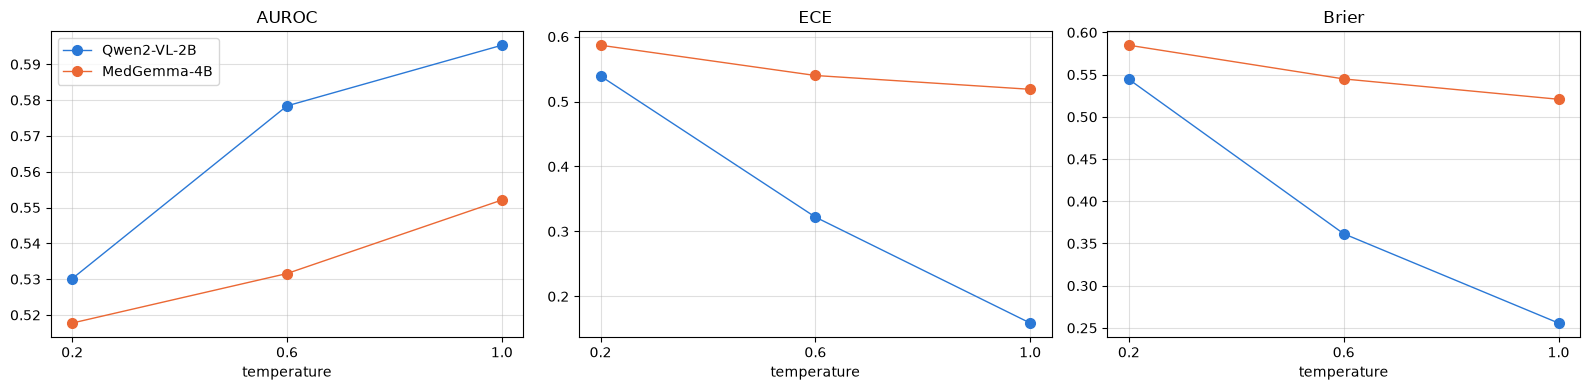

In [ ]:
#q9
import matplotlib.pyplot as plt
models = {"Qwen2-VL-2B": "Qwen2-VL-2B-Instruct", "MedGemma-4B": "medgemma-4b-it",}
temperatures = [0.2, 0.6, 1.0]

results = []
for modelName, fileName in models.items():
    for temperature in temperatures:
        filePath = f"./data/model_responses/outputs_{fileName}-temp_{temperature}.tsv"
        configDf = load_and_process_data(filePath)
        uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)
        auroc, ece, brierScore = compute_calibration_metrics(uncertainties, correctness)
        #append everything later decide what we use
        results.append({"model": modelName, "temperature": temperature, "accuracy": correctness.mean(), "AUROC": auroc, "ECE": ece, "Brier": brierScore,})

resultsDf = pd.DataFrame(results)
print(resultsDf.round(3).to_string(index=False))
metrics = ["AUROC", "ECE", "Brier"]
colors = {"Qwen2-VL-2B": "#2a78d6", "MedGemma-4B": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, metric in enumerate(metrics):
    ax = axes[i]
    for modelName in models:
        modelRows = resultsDf[resultsDf["model"] == modelName]
        ax.plot(modelRows["temperature"], modelRows[metric], marker="o", markersize=7,linewidth=1,color=colors[modelName], label=modelName)
    ax.set_title(metric)
    ax.set_xlabel("temperature")
    ax.set_xticks(temperatures)
    ax.grid(alpha=0.4)

axes[0].legend()
plt.tight_layout()
plt.show()

In [33]:
#q10
import math
from sklearn.metrics import roc_auc_score
filePaths = [
    "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv",]
nBins = 10

for filePath in filePaths:
    configDf = load_and_process_data(filePath)
    # prob of the option label token
    labelProbs = []
    for logprobs in configDf['logprobs']:
        labelProb = 0
        for token, logprob in ast.literal_eval(logprobs):
            if re.search(r'\[[A-E]', token):
                labelProb = math.exp(logprob)
                break
        labelProbs.append(labelProb)
    configDf['label_prob'] = labelProbs
    
    #sum label probs per letter then confidence is share of the majority letter (so devide majority letter prob/all probs)
    confidences = []
    correctness = []
    #per quesiton of course
    for index, group in configDf.groupby('index'):
        letterList = {}
        for letter, labelProb in zip(group['parsed_response'], group['label_prob']):
            if pd.isna(letter):
                continue
            if letter in letterList:
                letterList[letter] += labelProb
            else:
                letterList[letter] = labelProb

        majorityAnswer = Counter(group['parsed_response']).most_common(1)[0][0]
        totalProb = sum(letterList.values())
        if pd.isna(majorityAnswer) or totalProb == 0:
            confidence = 0
        else:
            confidence = letterList[majorityAnswer] / totalProb

        confidences.append(confidence)
        correctness.append(1 if majorityAnswer == group['gold_label'].iloc[0] else 0)
    confidences = np.array(confidences)
    correctness = np.array(correctness)
    auroc = roc_auc_score(1 - correctness, 1 - confidences)

    # ECE on the confidence itself not with above code ad no min/max scaling (we already have normal confidence between 0 adn 1)
    binEdges = np.linspace(0, 1, nBins + 1)
    ece = 0
    for i in range(nBins):
        inBin = (confidences >= binEdges[i]) & (confidences < binEdges[i + 1])
        if i == nBins - 1:
            inBin = (confidences >= binEdges[i]) & (confidences <= binEdges[i + 1])
        if inBin.sum() > 0:
            binAccuracy = correctness[inBin].mean()
            binConfidence = confidences[inBin].mean()
            ece += inBin.sum() / len(confidences) * abs(binAccuracy - binConfidence)

    brierScore = np.mean((confidences - correctness) ** 2)

    print(os.path.basename(filePath))
    print(f"  majority vote accuracy: {correctness.mean():.3f}")
    print(f"  mean confidence: {confidences.mean():.3f}")
    print(f"  AUROC: {auroc:.3f}")
    print(f"  ECE: {ece:.3f}")
    print(f"  Brier score: {brierScore:.3f}")
    
    
print("!!CONFIDENT BUT WRONG")
wrongRows = configDf[configDf['parsed_response'] != configDf['gold_label']]
print(wrongRows.sort_values('label_prob', ascending=False)[[ 'label_prob', 'response']].head(10).to_string())

print("\n!!LONGEST RESPONSES")
configDf['response_length'] = configDf['response'].str.len()
print(configDf.sort_values('response_length', ascending=False)[[ 'label_prob', 'response']].head(10).to_string())

print("\n!!NOT STARTING WITH THE LABEL")
notStartingWithLabel = configDf[~configDf['response'].str.strip().str.startswith('[')]
print(notStartingWithLabel[[ 'label_prob', 'response']].head(10).to_string())

outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
  majority vote accuracy: 0.320
  mean confidence: 0.802
  AUROC: 0.561
  ECE: 0.482
  Brier score: 0.477
outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv
  majority vote accuracy: 0.523
  mean confidence: 0.970
  AUROC: 0.548
  ECE: 0.455
  Brier score: 0.449
outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv
  majority vote accuracy: 0.510
  mean confidence: 0.913
  AUROC: 0.615
  ECE: 0.403
  Brier score: 0.404
outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv
  majority vote accuracy: 0.517
  mean confidence: 0.883
  AUROC: 0.672
  ECE: 0.379
  Brier score: 0.373
!!CONFIDENT BUT WRONG
      label_prob                                                                                                                                                                                                                                                                                                                           response
1779    0.989545                     

In [37]:
#Q11
filePaths = [
    "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv",
]
for filePath in filePaths:
    configDf = load_and_process_data(filePath)
    embeddingPath = filePath.replace("model_responses/outputs_", "embeddings/embeddings_").replace(".tsv", ".npy")
    embeddings = np.load(embeddingPath)
    rdsScores = []
    correctness = []
    
    for index, group in configDf.groupby('index'):
        # same index between two
        questionEmbeddings = embeddings[group.index]
        #vector length one first step in papaer
        questionEmbeddings = questionEmbeddings / np.linalg.norm(questionEmbeddings, axis=1, keepdims=True)
        #want to compare to centroida
        centroid = questionEmbeddings.mean(axis=0)
        rds = 0
        for embedding in questionEmbeddings:
            rds += np.abs(embedding - centroid).sum()
        rdsScores.append(rds)
        
        majorityAnswer = Counter(group['parsed_response']).most_common(1)[0][0]
        correctness.append(1 if majorityAnswer == group['gold_label'].iloc[0] else 0)

    rdsScores = np.array(rdsScores)
    correctness = np.array(correctness)
    auroc, ece, brierScore = compute_calibration_metrics(rdsScores, correctness)

    print(os.path.basename(filePath))
    print(f"  majority vote accuracy: {correctness.mean():.3f}")
    print(f"  AUROC: {auroc:.3f}")
    print(f"  ECE: {ece:.3f}")
    print(f"  Brier score: {brierScore:.3f}")

# identical embeds gives 0 (just like shannon)
identicalEmbeddings = np.repeat(embeddings[:1], 10, axis=0)
identicalEmbeddings = identicalEmbeddings / np.linalg.norm(identicalEmbeddings, axis=1, keepdims=True)
centroid = identicalEmbeddings.mean(axis=0)
rds = 0
for embedding in identicalEmbeddings:
    rds += np.abs(embedding - centroid).sum()
print("\nRDS for 10 identical embeddings (expected 0):", rds)

outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
  majority vote accuracy: 0.320
  AUROC: 0.509
  ECE: 0.272
  Brier score: 0.333
outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv
  majority vote accuracy: 0.523
  AUROC: 0.510
  ECE: 0.167
  Brier score: 0.297
outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv
  majority vote accuracy: 0.510
  AUROC: 0.582
  ECE: 0.123
  Brier score: 0.262
outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv
  majority vote accuracy: 0.517
  AUROC: 0.642
  ECE: 0.132
  Brier score: 0.252

RDS for 10 identical embeddings (expected 0): 9.471405e-06


In [ ]:
#q12
filePath = "/content/data/model_responses/outputs_medgemma-4b-it-temp_0.2.tsv"
configDf = load_and_process_data(filePath)

for modality, modalityDF in configDf.groupby('modality'):
  uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(modalityDF)

  n_questions = len(correctness)
  accuracy = correctness.mean()

  auroc, ece, brierScore = compute_calibration_metrics(uncertainties, correctness)

  print(os.path.basename(filePath))
  print(f"Modality: {modality}")
  print(f"  Accuracy: {accuracy:.3f}")
  print(f"  AUROC: {auroc:.3f}")
  print(f"  ECE: {ece:.3f}")
  print(f"  Brier score: {brierScore:.3f}")

counts = configDf.groupby('modality', dropna=False).agg(
    n_questions=('index', 'nunique'),
    n_answers=('index', 'size')
)

print(counts)


In [ ]:
#q13
filePaths = [
    "/content/data/model_responses/outputs_gpt5-mini_no-logprobs.tsv",
    "/content/data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
]

for filePath in filePaths:
    configDf = load_and_process_data(filePath)

    uncertainties, correctness, numOptions = (compute_semantic_entropy_uncertainty(configDf))

    auroc, ece, brierScore = compute_calibration_metrics(uncertainties, correctness)

    print(os.path.basename(filePath))
    print(f"  Number of questions: {len(correctness)}")
    print(f"  Number of sampled responses: {len(configDf)}")
    print(f"  Majority-vote accuracy: {correctness.mean():.3f}")
    print(f"  AUROC: {auroc:.3f}")
    print(f"  ECE: {ece:.3f}")
    print(f"  Brier score: {brierScore:.3f}")
    print()

In [ ]:
#q14
from IPython.display import display
import os

filePaths = {
    "GPT-5-mini (temperature unknown)": "/content/data/model_responses/outputs_gpt5-mini_no-logprobs.tsv",
    "Qwen2.5-32B (temperature 0.6)": "/content/data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
    "Qwen2-2B (temperature 0.6)": "/content/data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv",
    "MedGemma-4B (temperature 0.6)": "/content/data/model_responses/outputs_medgemma-4b-it-temp_0.6.tsv",
}

modelDfs = {}
results = []
for modelName, filePath in filePaths.items():
    configDf = load_and_process_data(filePath)
    modelDfs[modelName] = configDf
    uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)

    for (index, group), entropy, correct in zip(configDf.groupby('index'), uncertainties, correctness):
        majorityAnswer = Counter(group['parsed_response']).most_common(1)[0][0]
        results.append({
            'index': index, 'model': modelName,
            'prediction': majorityAnswer if majorityAnswer is not None else 'unparsed',
            'correct': correct, 'entropy': entropy,
        })

resultsDf = pd.DataFrame(results)

# Keep questions present in all models
sharedIds = resultsDf.groupby('index').size()
resultsDf = resultsDf[resultsDf['index'].isin(sharedIds[sharedIds == 4].index)]
summary = resultsDf.groupby('index').agg(n_correct=('correct', 'sum'), n_answers=('prediction', 'nunique'))

if len(summary) < 3:
    raise ValueError('At least three shared questions are needed.')

# First part of the question, all wrong, or the largest disagreement
allWrong = summary[summary['n_correct'] == 0]
if len(allWrong) > 0:
    firstId = allWrong.index[0]
else:
    print('No shared error exists; selecting the largest disagreement instead.')
    firstId = summary['n_answers'].idxmax()

# Second part of the question, a different question prompt with disagreement
remaining = summary.drop(firstId)
disagree = remaining[remaining['n_answers'] > 1]
if len(disagree) > 0:
    secondId = disagree['n_answers'].idxmax()
else:
    print('No additional disagreement exists; selecting an agreement case instead.')
    secondId = remaining.index[0]

# Third part of the question, an incorrect prediction with low entropy
remainingResults = resultsDf[~resultsDf['index'].isin([firstId, secondId])]
wrong = remainingResults[remainingResults['correct'] == 0]
if len(wrong) > 0:
    thirdId = wrong.sort_values('entropy')['index'].iloc[0]
else:
    print('Remaining questions are correct for all models; selecting one as the third case.')
    thirdId = remainingResults['index'].iloc[0]

for questionId in [firstId, secondId, thirdId]:
    print('\nQUESTION ID:', questionId)
    print(resultsDf[resultsDf['index'] == questionId].round(3).to_string(index=False))

    firstDf = next(iter(modelDfs.values()))
    row = firstDf[firstDf['index'] == questionId].iloc[0]
    print('Question:', row['question'])
    print('Options:', row['options'])
    print('Reference answer:', row['gold_label'])


    image_filename = os.path.basename(row['image_path'])
    display(Image.open(os.path.join('/content/data/images', image_filename)))

    for modelName, configDf in modelDfs.items():
        group = configDf[configDf['index'] == questionId]
        print('\n', modelName)
        print('Answer counts:', Counter(group['parsed_response']))
        for response in group['response'].unique():
            print(response)

In [ ]:
#q15
filePaths = {
    'GPT-5-mini (temperature unknown)': '/content/data/model_responses/outputs_gpt5-mini_no-logprobs.tsv',
    'Qwen2.5-32B (temperature 0.6)': '/content/data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv',
}

modelDfs = {
    modelName: load_and_process_data(filePath) for modelName, filePath in filePaths.items()
}

sharedQuestions = set.intersection(*(set(configDf['index']) for configDf in modelDfs.values()))

if not sharedQuestions:
    raise ValueError('No shared questions found.')

results = []
binResults = []

for modelName, configDf in modelDfs.items():
    configDf = configDf[configDf['index'].isin(sharedQuestions)]
    uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)

    # Normalize once
    uMin, uMax = uncertainties.min(), uncertainties.max()
    if uMax > uMin:
        scaledUncertainties = (uncertainties - uMin) / (uMax - uMin)
    else:
        scaledUncertainties = np.zeros_like(uncertainties)
    confidences = 1 - scaledUncertainties

    for nBins in [5, 10, 20]:
        binEdges = np.linspace(0, 1, nBins + 1)
        ece = 0

        for i in range(nBins):
            inBin = (confidences >= binEdges[i]) & (confidences < binEdges[i + 1])
            # Include confidence 1 in the last bin
            if i == nBins - 1:
                inBin = (confidences >= binEdges[i]) & (confidences <= binEdges[i + 1])

            count = inBin.sum()
            if count > 0:
                binConfidence = confidences[inBin].mean()
                binAccuracy = correctness[inBin].mean()
                ece += count / len(confidences) * abs(binAccuracy - binConfidence)
            else:
              binConfidence = np.nan
              binAccuracy = np.nan


            binResults.append({
                'model': modelName, 'bins': nBins,
                'lower': binEdges[i], 'upper': binEdges[i + 1],
                'count': count, 'mean confidence': binConfidence,
                'accuracy': binAccuracy,
            })

        results.append({'model': modelName, 'bins': nBins, 'ECE': ece})

resultsDf = pd.DataFrame(results)
binDf = pd.DataFrame(binResults)

print('ECE comparison')
print(resultsDf.pivot(index='model', columns='bins', values='ECE').round(3).to_string())

print('\nBin counts, confidence, and accuracy')
print(binDf.round(3).to_string(index=False))

In [ ]:
#rerun the codeblock just below a. Inference with Qwen2-VL-2B-Instruct first, then run this codeblock. We use the Qwen inference.
#q16
inputDf = pd.read_csv('/content/data/GMAI_mm_bench_dataset.tsv', sep='\t')
inputDf = add_options_dict(inputDf)

# need at least 3 options for 3 different shuffles
inputDf = inputDf[inputDf['options'].apply(len) >= 3]
subsetDf = inputDf.sample(n=50, random_state=42).sort_values('index')

conditions = ['original', 'shuffle1', 'shuffle2', 'shuffle3', 'original_repeat']
conditionData = {condition: [] for condition in conditions}
rng = random.Random(42)
sampleAnswers = 10
batchSize = 4
temperature = 0.6
topP = 0.9
maxNewTokens = 32

for _, row in subsetDf.iterrows():
    originalOptions = row['options']
    letters = list(originalOptions)

    # choose 3 different orders, excluding the original
    possibleOrders = list(permutations(letters))
    possibleOrders.remove(tuple(letters))
    orders = [tuple(letters)] + rng.sample(possibleOrders, 3) + [tuple(letters)]

    for condition, order in zip(conditions, orders):
        item = row.to_dict()
        labelMap = dict(zip(letters, order))
        newOptions = {}
        for newLetter, oldLetter in labelMap.items():
            newOptions[newLetter] = originalOptions[oldLetter]
        item['answer'] = letters[order.index(row['answer'])]

        # update the option columns too, because construct_prompt uses them
        item.update(newOptions)
        item['options'] = newOptions
        item['label_map'] = labelMap
        item['condition'] = condition
        item['prompt'] = construct_prompt(item)
        conditionData[condition].extend([item] * sampleAnswers)

# left padding for batched generation with Qwen
processor.tokenizer.padding_side = 'left'

results = []
# repeat the original with a different seed
seeds = [123, 123, 123, 123, 456]
for condition, seed in zip(conditions, seeds):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    data = conditionData[condition]

    for i in tqdm(range(0, len(data), batchSize), desc=condition):
        batch = data[i:i + batchSize]
        prompts = []
        images = []
        for item in batch:
            messages = [{'role': 'user', 'content': [
                {'type': 'text', 'text': item['prompt']},
                {'type': 'image'},
            ]}]
            prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
            prompts.append(prompt)
            imagePath = os.path.join('/content/data/images', os.path.basename(item['image_path']))
            with Image.open(imagePath) as image:
                images.append(image.convert('RGB'))

        inputs = processor(
            images=images, text=prompts, return_tensors='pt', padding=True
        ).to(model.device)
        with torch.no_grad():
            outputs = model.generate(
                **inputs, max_new_tokens=maxNewTokens,
                do_sample=True, temperature=temperature, top_p=topP,
                pad_token_id=processor.tokenizer.pad_token_id,
            )
        inputLength = inputs['input_ids'].shape[1]
        responses = processor.batch_decode(outputs[:, inputLength:], skip_special_tokens=True)

        for item, response in zip(batch, responses):
            results.append({
                'index': item['index'], 'condition': condition,
                'question': item['question'], 'image_path': item['image_path'],
                'options': item['options'], 'label_map': item['label_map'],
                'gold_label': item['answer'], 'response': response,
            })

os.makedirs('/content/outputs', exist_ok=True)
outputPath = '/content/outputs/option_order_Qwen2-VL-2B.tsv'
pd.DataFrame(results).to_csv(outputPath, sep='\t', index=False)
print('Saved:', outputPath)

In [ ]:
#q16 analysis
outputPath = '/content/outputs/option_order_Qwen2-VL-2B.tsv'
experimentDf = load_and_process_data(outputPath)
conditions = ['original', 'shuffle1', 'shuffle2', 'shuffle3', 'original_repeat']
results = []
predictions = []

for condition in conditions:
    configDf = experimentDf[experimentDf['condition'] == condition].copy()

    # letters outside the available options count as unparsed
    parsedAnswers = []
    for letter, options in zip(configDf['parsed_response'], configDf['options']):
        options = ast.literal_eval(options)
        parsedAnswers.append(letter if letter in options else None)
    configDf['parsed_response'] = parsedAnswers

    uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)
    auroc, ece, brierScore = compute_calibration_metrics(uncertainties, correctness)
    results.append({
        'condition': condition, 'accuracy': correctness.mean(),
        'AUROC': auroc, 'ECE': ece, 'Brier': brierScore,
    })

    for (index, group), entropy in zip(configDf.groupby('index'), uncertainties):
        majorityAnswer = Counter(group['parsed_response']).most_common(1)[0][0]
        labelMap = ast.literal_eval(group['label_map'].iloc[0])
        options = ast.literal_eval(group['options'].iloc[0])
        # give the unparsed group an explicit name
        labelMap[None] = 'unparsed'
        options[None] = 'unparsed'
        predictions.append({
            'index': index, 'condition': condition,
            'letter': majorityAnswer,
            'original_option': labelMap[majorityAnswer],
            'answer_content': options[majorityAnswer],
            'entropy': entropy,
        })

resultsDf = pd.DataFrame(results).set_index('condition')
print('Metrics')
print(resultsDf.round(3).to_string())
print('\nChange from original')
print(resultsDf.subtract(resultsDf.loc['original']).round(3).to_string())

predictionDf = pd.DataFrame(predictions)
wideDf = predictionDf.pivot(index='index', columns='condition', values='original_option')
print('\nAnswer changes compared with orginal')
for condition in conditions[1:]:
    changed = wideDf[condition] != wideDf['original']
    print(f'{condition}: {changed.sum()} / {len(wideDf)}')

# find a question where the actual answer content changes
contentDf = predictionDf.pivot(index='index', columns='condition', values='answer_content')
changedIds = []
for index, row in contentDf.iterrows():
    for condition in ['shuffle1', 'shuffle2', 'shuffle3']:
        if (row['original'] != 'unparsed' and row[condition] != 'unparsed'
                and row[condition] != row['original']):
            changedIds.append(index)
            break

if changedIds:
    questionId = changedIds[0]
    questionRows = experimentDf[experimentDf['index'] == questionId]
    row = questionRows[questionRows['condition'] == 'original'].iloc[0]
    print('\nQuestion:', questionId)
    print('Question:', row['question'])
    print('Original options:', row['options'])
    print('Reference:', row['gold_label'])
    print(predictionDf[predictionDf['index'] == questionId].round(3).to_string(index=False))
    imagePath = os.path.join('/content/data/images', os.path.basename(row['image_path']))
    display(Image.open(imagePath))

    for condition in conditions:
        group = questionRows[questionRows['condition'] == condition]
        print('\n', condition)
        print('Options:', group['options'].iloc[0])
        print('Reference:', group['gold_label'].iloc[0])
        for response in group['response'].unique():
            print(response)

In [ ]:
#q17
inputDf = pd.read_csv('/content/data/GMAI_mm_bench_dataset.tsv', sep='\t')
inputDf = add_options_dict(inputDf)
inputDf['prompt'] = inputDf.apply(construct_prompt, axis=1)
inputDf['image_file'] = inputDf['image_path'].apply(os.path.basename)
subsetDf = inputDf.sample(n=50, random_state=42).sort_values('index').copy()

# randomly choose a different image for each question, then keep it fixed
rng = random.Random(42)
unrelatedImages = []
for _, row in subsetDf.iterrows():
    otherImages = inputDf.loc[
        inputDf['image_file'] != row['image_file'], 'image_file'
    ].unique().tolist()
    unrelatedImages.append(rng.choice(otherImages))
subsetDf['unrelated_image'] = unrelatedImages

conditions = ['original', 'no_image', 'unrelated']
sampleAnswers = 10
batchSize = 4
temperature = 0.6
topP = 0.9
maxNewTokens = 32
processor.tokenizer.padding_side = 'left'

results = []
for condition in conditions:
    # same starting seed for all conditions
    torch.manual_seed(123)
    torch.cuda.manual_seed_all(123)
    data = [item for item in subsetDf.to_dict('records') for _ in range(sampleAnswers)]

    for i in tqdm(range(0, len(data), batchSize), desc=condition):
        batch = data[i:i + batchSize]
        prompts = []
        images = []
        for item in batch:
            content = [{'type': 'text', 'text': item['prompt']}]
            if condition != 'no_image':
                content.append({'type': 'image'})
                imageFile = item['image_file']
                if condition == 'unrelated':
                    imageFile = item['unrelated_image']
                imagePath = os.path.join('/content/data/images', imageFile)
                with Image.open(imagePath) as image:
                    images.append(image.convert('RGB'))

            messages = [{'role': 'user', 'content': content}]
            prompts.append(processor.apply_chat_template(
                messages, add_generation_prompt=True
            ))

        # no image placeholder or image input in the no-image condition
        if condition == 'no_image':
            inputs = processor(text=prompts, padding=True, return_tensors='pt')
        else:
            inputs = processor(
                text=prompts, images=images, padding=True, return_tensors='pt'
            )
        inputs = inputs.to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs, max_new_tokens=maxNewTokens,
                do_sample=True, temperature=temperature, top_p=topP,
                pad_token_id=processor.tokenizer.pad_token_id,
            )
        inputLength = inputs['input_ids'].shape[1]
        responses = processor.batch_decode(outputs[:, inputLength:], skip_special_tokens=True)

        for item, response in zip(batch, responses):
            results.append({
                'index': item['index'], 'condition': condition,
                'question': item['question'], 'options': item['options'],
                'gold_label': item['answer'], 'response': response,
                'image_path': item['image_file'],
                'unrelated_image': item['unrelated_image'],
                'task': item['clinical VQA task'],
            })

os.makedirs('/content/outputs', exist_ok=True)
outputPath = '/content/outputs/image_conditions_Qwen2-VL-2B.tsv'
pd.DataFrame(results).to_csv(outputPath, sep='\t', index=False)
print('Saved:', outputPath)

In [ ]:
#q17 analysis
outputPath = '/content/outputs/image_conditions_Qwen2-VL-2B.tsv'
experimentDf = load_and_process_data(outputPath)
conditions = ['original', 'no_image', 'unrelated']
results = []
questionResults = []

for condition in conditions:
    configDf = experimentDf[experimentDf['condition'] == condition].copy()

    # invalid letters stay in one unparsed group and counted as incorrect
    configDf['parsed_response'] = [
        letter if letter in ast.literal_eval(options) else None
        for letter, options in zip(configDf['parsed_response'], configDf['options'])
    ]
    uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)
    results.append({
        'condition': condition, 'accuracy': correctness.mean(),
        'mean entropy': uncertainties.mean(),
    })

    for (index, group), entropy, correct in zip(
        configDf.groupby('index'), uncertainties, correctness
    ):
        majorityAnswer = Counter(group['parsed_response']).most_common(1)[0][0]
        options = ast.literal_eval(group['options'].iloc[0])
        options[None] = 'unparsed'
        questionResults.append({
            'index': index, 'condition': condition,
            'prediction': majorityAnswer,
            'answer_content': options[majorityAnswer],
            'correct': correct, 'entropy': entropy,
            'task': group['task'].iloc[0],
        })

resultsDf = pd.DataFrame(results).set_index('condition')
print('ACCURACY AND UNCERTAINTY')
print(resultsDf.round(3).to_string())
print('\nCHANGE FROM ORIGINAL')
print(resultsDf.subtract(resultsDf.loc['original']).round(3).to_string())

questionDf = pd.DataFrame(questionResults)
print('\nRESULTS PER QUESTION TYPE')
print(questionDf.groupby(['task', 'condition']).agg(
    n_questions=('index', 'size'),
    accuracy=('correct', 'mean'),
    mean_entropy=('entropy', 'mean'),
).round(3).to_string())

# examine 3 questions with the largest accuracy or entropy differences
accuracyDf = questionDf.pivot(index='index', columns='condition', values='correct')
entropyDf = questionDf.pivot(index='index', columns='condition', values='entropy')
caseDf = pd.DataFrame({
    'accuracy_change': accuracyDf.subtract(accuracyDf['original'], axis=0).abs().max(axis=1),
    'entropy_change': entropyDf.subtract(entropyDf['original'], axis=0).abs().max(axis=1),
})
caseIds = caseDf.sort_values(
    ['accuracy_change', 'entropy_change'], ascending=False
).head(3).index

for questionId in caseIds:
    questionRows = experimentDf[experimentDf['index'] == questionId]
    row = questionRows.iloc[0]
    print('\nQUESTION:', questionId)
    print('Question:', row['question'])
    print('Options:', row['options'])
    print('Reference:', row['gold_label'])
    print(questionDf[questionDf['index'] == questionId].round(3).to_string(index=False))

    print('Original image:')
    display(Image.open(os.path.join('/content/data/images', row['image_path'])))
    print('Unrelated image:')
    display(Image.open(os.path.join('/content/data/images', row['unrelated_image'])))

    for condition in conditions:
        group = questionRows[questionRows['condition'] == condition]
        print('\n', condition)
        print('Answer counts:', Counter(group['parsed_response']))
        for response in group['response'].unique():
            print(response)

In [22]:
#Q18
#using temp 1 qwen outputs
filePath = "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv"
configDf = load_and_process_data(filePath)
uncertainties, correctness, numOptions = compute_semantic_entropy_uncertainty(configDf)

# split on question
rng = np.random.default_rng(42)
order = rng.permutation(len(uncertainties))
nVal = int(0.7 * len(order))
valIds = order[:nVal]
testIds = order[nVal:]
valUnc, valCorrect = uncertainties[valIds], correctness[valIds]
testUnc, testCorrect = uncertainties[testIds], correctness[testIds]
print(f"validation questions: {len(valIds)}, test questions: {len(testIds)}")
#questions with the same all answered or referred
thresholds = [np.inf] + sorted(np.unique(valUnc), reverse=True)
bestThreshold = np.inf
bestAccuracy = valCorrect.mean()
print(f'20 percent is {nVal*0.2}')
print('\n')
for threshold in thresholds:
    referred = valUnc >= threshold
    referral = referred.mean()#fraction true values
    accuracy = valCorrect[~referred].mean()
    print(f"threshold: {threshold:.3f}, referred: {referred.sum()}, referral: {referral:.3f}, answered acc: {accuracy:.3f}")
    if referral >= 0.2:
        break
    if accuracy > bestAccuracy:
        bestThreshold = threshold
        bestAccuracy = accuracy

valReferral = (valUnc >= bestThreshold).mean()
print(f"\nchosen threshold: {bestThreshold:.3f}, validation referral: {valReferral:.3f}, validation answered acc: {bestAccuracy:.3f}")

# same threshold on test
testReferred = testUnc >= bestThreshold
nReferred = testReferred.sum()
testAnswered = testCorrect[~testReferred]
testAccuracy = testAnswered.mean()
testUnflagged = (testAnswered == 0).sum()
print(f"\n!!!!!TEST")
print(f"accuracy without referral: {testCorrect.mean():.3f}, incorrect answers: {(testCorrect == 0).sum()}")
print(f"referred: {nReferred}/{len(testCorrect)}, referral proportion: {testReferred.mean():.3f}")
print(f"coverage: {1 - testReferred.mean():.3f}")
print(f"accuracy answered: {testAccuracy:.3f}")
print(f"incorrect answers unflagged: {testUnflagged}")

# random referral of the same number of test questions
randomAccuracies = []
randomUnflagged = []
for i in range(100):
    randomReferred = rng.choice(len(testCorrect), nReferred, replace=False)
    randomAnswered = np.delete(testCorrect, randomReferred)
    randomAccuracies.append(randomAnswered.mean())
    randomUnflagged.append((randomAnswered == 0).sum())
randomAccuracies = np.array(randomAccuracies)
randomUnflagged = np.array(randomUnflagged)

print(f"\n!!!!RANDOM REFERRAL ({nReferred} questions, 100 repeats)")
print(f"  accuracy among answered: mean {randomAccuracies.mean():.3f}, std {randomAccuracies.std():.3f}")
print(f"  incorrect left unflagged: mean {randomUnflagged.mean():.1f}, std {randomUnflagged.std():.1f}")
print(f"  referral amount: {nReferred}/{len(testCorrect)}")
print(f"  referral proportion: {nReferred / len(testCorrect):.3f}")
print(f"  coverage: {1 - nReferred / len(testCorrect):.3f}")

validation questions: 210, test questions: 90
20 percent is 42.0


threshold: inf, referred: 0, referral: 0.000, answered acc: 0.529
threshold: 1.922, referred: 2, referral: 0.010, answered acc: 0.534
threshold: 1.895, referred: 4, referral: 0.019, answered acc: 0.539
threshold: 1.846, referred: 5, referral: 0.024, answered acc: 0.537
threshold: 1.761, referred: 6, referral: 0.029, answered acc: 0.539
threshold: 1.685, referred: 9, referral: 0.043, answered acc: 0.542
threshold: 1.571, referred: 11, referral: 0.052, answered acc: 0.543
threshold: 1.571, referred: 12, referral: 0.057, answered acc: 0.545
threshold: 1.522, referred: 15, referral: 0.071, answered acc: 0.554
threshold: 1.485, referred: 18, referral: 0.086, answered acc: 0.552
threshold: 1.371, referred: 25, referral: 0.119, answered acc: 0.557
threshold: 1.361, referred: 31, referral: 0.148, answered acc: 0.559
threshold: 1.361, referred: 32, referral: 0.152, answered acc: 0.556
threshold: 1.357, referred: 33, referral: 0.